In [1]:
import pandas as pd
import numpy as np
import os
import sys
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
import joblib

# Add project root to path for module imports
sys.path.insert(0, os.path.abspath('..'))
from src.evaluation import evaluate_model, plot_roc_curves

# Load the processed datasets from the feature engineering step
X_train = pd.read_csv('../data/processed/X_train_resampled.csv')
y_train = pd.read_csv('../data/processed/y_train_resampled.csv').squeeze()
X_test = pd.read_csv('../data/processed/X_test.csv')
y_test = pd.read_csv('../data/processed/y_test.csv').squeeze()

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

Training set: 8278 samples
Test set: 1409 samples


In [8]:
# Define three candidate classifiers
models = {
    'Logistic Regression': LogisticRegression(max_iter=10000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

# 5-fold stratified cross-validation on the resampled training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Cross-Validation ROC-AUC Scores:")
print("-" * 45)
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    print(f"{name}: {scores.mean():.4f} (+/- {scores.std():.4f})")

Cross-Validation ROC-AUC Scores:
---------------------------------------------
Logistic Regression: 0.8908 (+/- 0.0056)
Random Forest: 0.9260 (+/- 0.0053)
Gradient Boosting: 0.9028 (+/- 0.0052)


In [17]:
# Train on full resampled training set, evaluate on held-out test set
results = []
fitted_models = {}

for name, model in models.items():
    # Fit the model on all resampled training data
    model.fit(X_train, y_train)
    # Evaluate using our reusable function
    metrics = evaluate_model(model, X_test, y_test, model_name=name)
    results.append(metrics)
    fitted_models[name] = model

# Display results as a comparison table
results_df = pd.DataFrame(results).set_index('model')
print(results_df.round(4))

                     roc_auc  precision  recall      f1
model                                                  
Logistic Regression   0.8257     0.5153  0.7219  0.6013
Random Forest         0.8211     0.5612  0.5882  0.5744
Gradient Boosting     0.8341     0.5386  0.7086  0.6120


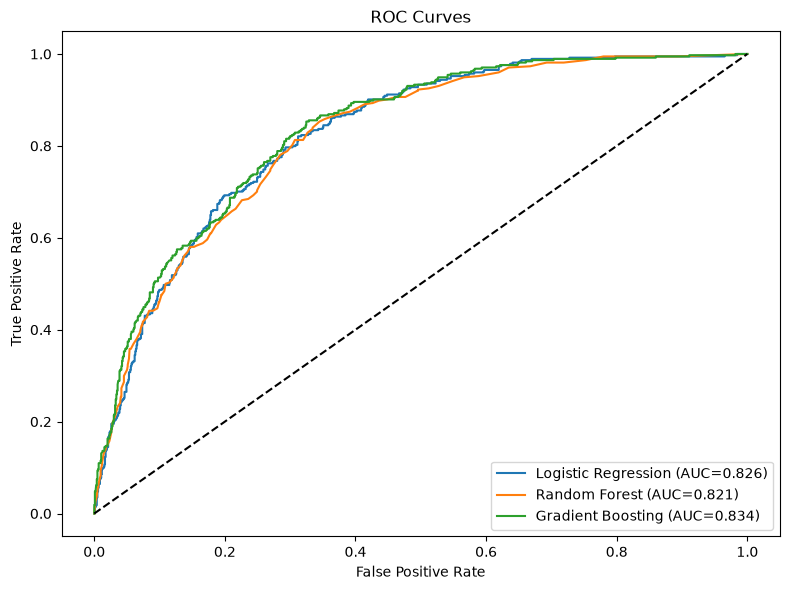

In [18]:
# Create output directories for figures and saved models
os.makedirs('../reports/figures', exist_ok=True)
os.makedirs('../models', exist_ok=True)

# Change to project root so plot_roc_curves saves to the correct path
original_dir = os.getcwd()
os.chdir('..')

# Plot ROC curves for all three models
plot_roc_curves(fitted_models, X_test, y_test)

# Return to notebooks directory
os.chdir(original_dir)

## Model Selection

**Best model: Gradient Boosting**

Why this model?
- **Highest ROC-AUC on the held-out test set** (0.834 vs. 0.826 for Logistic
  Regression and 0.821 for Random Forest). ROC-AUC is threshold-independent, so
  it compares how well each model ranks churners above non-churners without
  depending on the default 0.5 cutoff.
- **Highest F1 (0.612)**, with recall (0.709) within 0.013 of Logistic
  Regression's (0.722) and higher precision (0.539 vs. 0.515). Random Forest was
  ruled out: it has the lowest recall (0.588), meaning it misses about 41% of
  churners.
- **Recall is the priority for churn**, since a missed churner is a lost
  customer, while a false positive only costs a retention offer. Recall at a
  fixed threshold isn't a fixed property of a model, so the final decision
  threshold will be tuned to hit a target recall instead of using 0.5.

**Caveat:** the AUC gap between Gradient Boosting and Logistic Regression
(0.008) is within the noise of a single test split, so the two are effectively
tied. Gradient Boosting is chosen for its slightly better ranking and its
potential for tuning; Logistic Regression remains a reasonable choice if
interpretability is required.

**Next step:** tune the decision threshold using the precision-recall curve and
the relative cost of a false negative vs. a false positive.

In [20]:
# Select the best model based on ROC-AUC
best_model_name = results_df['roc_auc'].idxmax()
best_model = fitted_models[best_model_name]

# Save to models/ directory using joblib
joblib.dump(best_model, '../models/best_model.pkl')
print(f"Saved {best_model_name} to models/best_model.pkl")

Saved Gradient Boosting to models/best_model.pkl
